# Stein transport in parameter, projected and function coordinates
SVGD uses $\phi(x)=N^{-1}\sum_j[k(x_j,x)\nabla\log\pi(x_j)+\nabla_{x_j}k(x_j,x)]$. We compare weight-space SVGD, likelihood-informed pSVGD and the published block-diagonal SVN approximation on a whitened Gaussian inverse problem; then transport predictions through an actual function map and destination VJP. [R11](../docs/references.md#r11), [R12](../docs/references.md#r12), [R13](../docs/references.md#r13), [R14](../docs/references.md#r14).

In [1]:
import os, json, time, platform
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from lafa import samplers
from lafa.problems import Gaussian, GaussianMixture2D, Banana2D

torch.set_num_threads(1)
device = torch.device(os.environ.get('LAFA_DEVICE', 'cpu'))
if device.type == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('LAFA_DEVICE=cuda requested, but CUDA is unavailable')
dtype, seed = torch.float64, 2026
quick = os.environ.get('LAFA_QUICK', '1') == '1'
torch.manual_seed(seed)
def gen(offset=0):
    return torch.Generator(device=device).manual_seed(seed + offset)
def tensor(x): return torch.as_tensor(x, device=device, dtype=dtype)
def cpu(x): return x.detach().cpu().numpy()
def sync():
    if device.type == 'cuda': torch.cuda.synchronize(device)
def table(rows):
    keys = list(dict.fromkeys(k for row in rows for k in row))
    display(Markdown('| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n' +
        '\n'.join('| ' + ' | '.join(f'{r[k]:.4g}' if isinstance(r.get(k),float) else str(r.get(k, '—')) for k in keys) + ' |' for r in rows)))
def contour(ax, target, bounds=(-5,5,-5,5)):
    a=torch.linspace(bounds[0],bounds[1],100,device=device,dtype=dtype)
    b=torch.linspace(bounds[2],bounds[3],100,device=device,dtype=dtype)
    xx,yy=torch.meshgrid(a,b,indexing='xy')
    with torch.no_grad(): u=target(torch.stack((xx,yy),-1))
    ax.contour(cpu(xx),cpu(yy),cpu(u-u.min()),levels=[.5,1,2,4,8,16],colors='0.7',linewidths=.6)
    ax.set(xlim=bounds[:2],ylim=bounds[2:]); ax.set_aspect('equal')
def covariance(x):
    z=x-x.mean(0); return z.T@z/(len(x)-1)
def collect(method, steps, burn=0, thin=1):
    samples=[]; trace=[]; hs=[]; accepted=[]
    for i in range(steps):
        r=method.step(); trace.append(r.position.reshape(-1,r.position.shape[-1])[0].clone())
        hs.append(float(torch.as_tensor(r.stats.get('step_size',getattr(method,'step_size',float('nan')))).double().mean()))
        if getattr(r,'accepted',None) is not None: accepted.append(r.accepted.double().mean())
        if i>=burn and (i-burn)%thin==0: samples.append(r.position.reshape(-1,r.position.shape[-1]))
    return torch.cat(samples),torch.stack(trace),hs,float(torch.stack(accepted).mean()) if accepted else float('nan')
root=Path.cwd() if (Path.cwd()/'docs').exists() else Path.cwd().parent
assets=root/'docs'/'assets'; assets.mkdir(parents=True,exist_ok=True)
print(json.dumps(dict(device=str(device),dtype=str(dtype),seed=seed,quick=quick,torch=torch.__version__,python=platform.python_version(),hardware=torch.cuda.get_device_name(device) if device.type=='cuda' else platform.processor() or platform.machine())))


{"device": "cpu", "dtype": "torch.float64", "seed": 2026, "quick": true, "torch": "2.6.0+cpu", "python": "3.12.14", "hardware": "x86_64"}


In [2]:
from lafa.particles import SVGD,ProjectedSVGD,SteinVariationalNewton,FunctionSpaceSVGD
from lafa.kernels import RBF
D,N=8,24; iterations=55 if quick else 200
x=torch.randn((N,D),device=device,dtype=dtype,generator=gen())
y=tensor([1.,-.7]); sigma=.5
def log_likelihood(z): return -.5*((z[...,:2]-y)/sigma).square().sum(-1)
def potential(z): return z.square().sum(-1)/2-log_likelihood(z)
mean=torch.zeros(D,device=device,dtype=dtype); mean[:2]=y/(1+sigma*sigma)
variance=torch.ones(D,device=device,dtype=dtype); variance[:2]=sigma*sigma/(1+sigma*sigma)
truth_cov=torch.diag(variance)
methods={'w-SVGD':SVGD(potential,x,step_size=.07,kernel=RBF(2.)),
 'pSVGD rank 2':ProjectedSVGD(log_likelihood,x,rank=2,step_size=.07,kernel=RBF(1.)),
 'SVN block diagonal':SteinVariationalNewton(potential,x,step_size=.025,kernel=RBF(2.),damping=.01,cg_max_iterations=30)}
paths={}; rows=[]
for name,m in methods.items():
    path=[m.position]; calls=0; sync(); start=time.perf_counter()
    for _ in range(iterations):
        r=m.step(); path.append(r.position); calls+=int(r.stats.get('cg_operator_calls',0))
    sync(); elapsed=time.perf_counter()-start; paths[name]=torch.stack(path)
    rows.append(dict(method=name,seconds=elapsed,mean_error=float((m.position.mean(0)-mean).norm()),covariance_error=float((covariance(m.position)-truth_cov).norm()),HVP_operator_calls=calls))
table(rows)

| method | seconds | mean_error | covariance_error | HVP_operator_calls |
|---|---|---|---|---|
| w-SVGD | 0.05729 | 0.1659 | 0.7152 | 0 |
| pSVGD rank 2 | 0.05572 | 0.2899 | 1.073 | 0 |
| SVN block diagonal | 4.456 | 0.07341 | 0.6914 | 8052 |

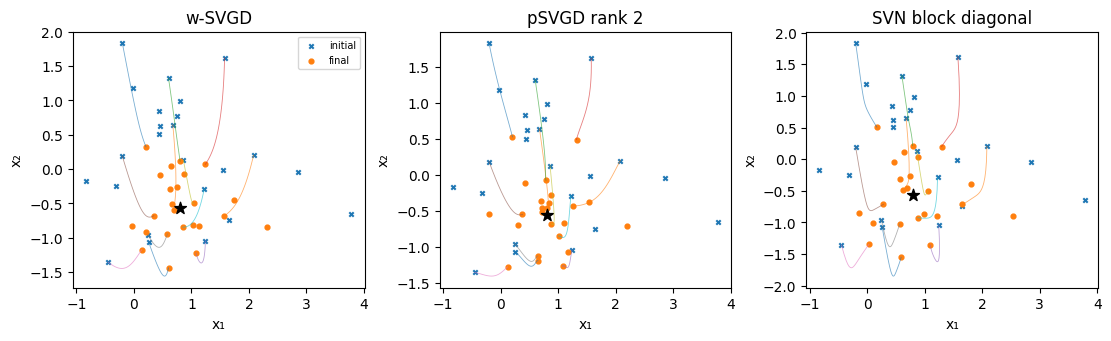

Projected likelihood basis residual: 9.39959687352353e-15


In [3]:
fig,ax=plt.subplots(1,3,figsize=(11,3.3),layout='constrained')
for a,(name,path) in zip(ax,paths.items()):
    for k in range(min(N,12)): a.plot(cpu(path[:,k,0]),cpu(path[:,k,1]),lw=.6,alpha=.6)
    a.scatter(*cpu(path[0,:,:2]).T,s=10,marker='x',label='initial'); a.scatter(*cpu(path[-1,:,:2]).T,s=12,label='final')
    a.scatter(*cpu(mean[:2]),marker='*',s=80,color='k'); a.set_title(name); a.set(xlabel='x₁',ylabel='x₂')
ax[0].legend(fontsize=7); plt.show()
print('Projected likelihood basis residual:',float(methods['pSVGD rank 2'].basis_residual))

All methods use the same particles and iteration count, but SVN performs additional matrix-free curvature solves. Reported operator calls count block-operator evaluations, each of which can contain several target HVPs. pSVGD keeps the prior-distributed complement supplied at initialization; its frozen-complement profile score is an approximation, not an unbiased optimal-profile score. Finite deterministic particles are not independent MCMC draws.

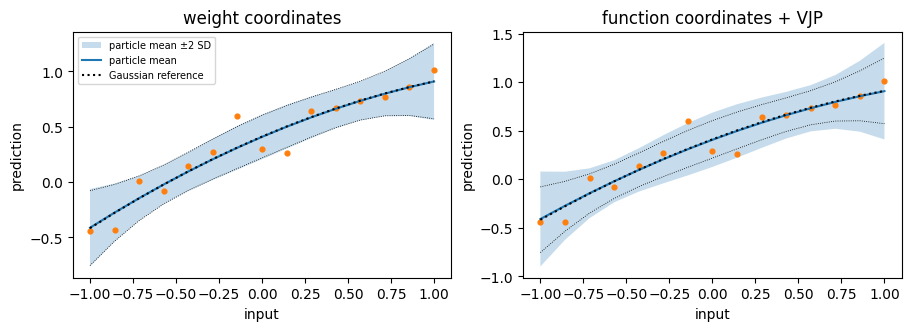

| coordinates | predictive_mean_RMSE | predictive_SD_RMSE |
|---|---|---|
| weight coordinates | 0.001926 | 0.003511 |
| function coordinates + VJP | 0.004468 | 0.04507 |

In [4]:
# Finite function-space Bayesian polynomial regression.
t=torch.linspace(-1,1,15,device=device,dtype=dtype)
G=torch.stack((torch.ones_like(t),t,t.square()),-1)
yfun=.4+.7*t-.2*t.square()+.15*torch.randn(t.shape,device=device,dtype=dtype,generator=gen(40))
noise_sd=.25; prior_sd=2.
def fmap(w): return G@w
def fpotential(f): return .5*((f-yfun)/noise_sd).square().sum(-1)+.5*(f/prior_sd).square().sum(-1)
weights=torch.randn((24,3),device=device,dtype=dtype,generator=gen(41))*.4
fmethod=FunctionSpaceSVGD(fmap,fpotential,weights,step_size=.0008,kernel=RBF(1.5))
wmethod=SVGD(lambda w:fpotential(w@G.T),weights,step_size=.004,kernel=RBF(.5))
regression_steps=250 if quick else 1000
for _ in range(regression_steps): fmethod.step(); wmethod.step()
# Exact reference for the induced parameter density proportional to exp(-Uf(Gw)).
precision=(1/noise_sd**2+1/prior_sd**2)*(G.T@G)
cov=torch.linalg.inv(precision); mu=torch.linalg.solve(precision,G.T@yfun/noise_sd**2)
reference_mean=G@mu; reference_sd=(G@cov@G.T).diagonal().sqrt()
fig,ax=plt.subplots(1,2,figsize=(9,3.2),layout='constrained')
rows=[]
for a,(name,m) in zip(ax,[('weight coordinates',wmethod),('function coordinates + VJP',fmethod)]):
    predictions=m.position@G.T; pm=predictions.mean(0); sd=predictions.std(0)
    a.fill_between(cpu(t),cpu(pm-2*sd),cpu(pm+2*sd),alpha=.25,label='particle mean ±2 SD')
    a.plot(cpu(t),cpu(pm),label='particle mean'); a.plot(cpu(t),cpu(reference_mean),'k:',label='Gaussian reference')
    a.plot(cpu(t),cpu(reference_mean-2*reference_sd),'k:',lw=.6); a.plot(cpu(t),cpu(reference_mean+2*reference_sd),'k:',lw=.6)
    a.scatter(cpu(t),cpu(yfun),s=12); a.set_title(name); a.set(xlabel='input',ylabel='prediction')
    rows.append(dict(coordinates=name,predictive_mean_RMSE=float((pm-reference_mean).square().mean().sqrt()),predictive_SD_RMSE=float((sd-reference_sd).square().mean().sqrt())))
ax[0].legend(fontsize=7); plt.show(); table(rows)

The fixed evaluation grid defines the function-space kernel and explicit function prior. The implementation maps each weight vector to predictions and pulls transport back with $J_i^T\phi_i$. It is not an inverse-Jacobian step: induced prediction drift is $J_iJ_i^T\phi_i$. A linear map is deliberately used so a Gaussian reference is available. Plotted ±2 SD bands summarize this finite ensemble; they are not calibrated coverage claims.